# Advertised-price model review

Read completed runs from `MODEL_OUTPUT/`. Set run parameters below; no training artifacts are changed.

Errors describe historical advertised prices, not sale prices or future-market performance. Cohort dimensions remain separate; evaluation holds out families or VINs within known families.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

def find_project_root(start=None):
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "MODELS" / "Price_ML_Models.py").is_file():
            return candidate
    raise FileNotFoundError("Run the notebook from inside E:/DataScience_Capstone_Cars.")

PROJECT_ROOT = find_project_root()
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from MODELS.Price_ML_Models import compatible_run_metadata, MODEL_FEATURE_SETS

MODEL_OUTPUT_DIR = PROJECT_ROOT / "MODEL_OUTPUT"
MODEL_TYPE = "base"   # Primary single-run diagnostics below.
COMPARISON_MODEL_TYPES = ["base", "enhanced", "enhanced_safety"]
RUN_PATH = None       # Optional explicit primary run folder.
RUN_PATHS = {}        # Optional {model_type: run folder}; otherwise newest completed run.
SHAP_ROW = 0          # row to inspect in the bounded SHAP sample


## Published app comparison

The app uses explicit report and predictor pins. Pilots and unfinished runs are excluded from full-budget rankings; validation selects estimators.

In [2]:
from car_app.model_registry import registry, verified_report
app_artifacts = registry()
feature_report = PROJECT_ROOT / app_artifacts["comparison_report"]
feature_receipt = verified_report(feature_report)
feature_inventory = pd.read_csv(feature_report / "inventory.csv")
feature_candidates = pd.read_csv(feature_report / "candidates.csv")
print("Activated price model:", app_artifacts.get("active_price", {}).get("run"), app_artifacts.get("active_price", {}).get("model"))
display(feature_inventory)
display(feature_candidates.drop(columns=["source_hashes"]).round(2))


2026-10-24 11:09:25.712 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-24 11:09:25.714 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-24 11:09:25.715 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-24 11:09:25.718 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-24 11:09:25.719 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


...

2026-10-24 11:09:25.722 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-24 11:09:25.726 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Activated price model: base/20261009T171630407257Z-full catboost


,variant,latest_run,latest_status,completed_full_run,status,group,completed_estimators,unavailable_estimators
0,base,20261009T171630407257Z-full,completed,20261009T171630407257Z-full,completed_full,303f779119677128,8.0,NaN
1,enhanced,20261011T050517300002Z-full,completed,20261011T050517300002Z-full,completed_full,303f779119677128,8.0,NaN
2,enhanced_safety,20261017T203431387661Z-full,completed,20261017T203431387661Z-full,completed_full,303f779119677128,5.0,NaN
3,full_youtube,20261009T162705962527Z-pilot-5000,completed,NaN,pilot_only,NaN,NaN,NaN
4,enhanced_safety_expert,20261009T162616955330Z-pilot-5000,completed,NaN,pilot_only,NaN,NaN,NaN
5,enhanced_safety_expert_coverage,20261009T162641875002Z-pilot-5000,completed,NaN,pilot_only,NaN,NaN,NaN
6,full_youtube_expert_coverage,20261009T162731412889Z-pilot-5000,completed,NaN,pilot_only,NaN,NaN,NaN
7,full,20261020T212804243364Z-full,running,NaN,awaiting_completed_full,NaN,NaN,NaN


,variant,run,model,group,validation_mae,test_mae,test_rmse,elapsed_seconds,feature_count
0,base,base/20261009T171630407257Z-full,catboost,303f779119677128,2586.08,2409.52,8109.45,43847.54,39
1,enhanced,enhanced/20261011T050517300002Z-full,catboost,303f779119677128,2677.65,2604.96,8440.49,75848.04,93
2,enhanced,enhanced/20261011T050517300002Z-full,lightgbm,303f779119677128,2990.34,2740.69,9196.12,2739.45,93
3,base,base/20261009T171630407257Z-full,lightgbm,303f779119677128,2991.54,2726.79,8984.13,3826.34,39
4,base,base/20261009T171630407257Z-full,xgboost,303f779119677128,3152.93,2993.65,9544.24,3081.04,39
5,enhanced,enhanced/20261011T050517300002Z-full,xgboost,303f779119677128,3153.86,2974.15,9397.13,4135.32,93
6,enhanced_safety,enhanced_safety/20261017T203431387661Z-full,random_forest,303f779119677128,3169.04,3066.22,8834.56,256002.38,113
7,base,base/20261009T171630407257Z-full,random_forest,303f779119677128,3187.87,3011.22,8976.36,76563.94,39
8,enhanced,enhanced/20261011T050517300002Z-full,random_forest,303f779119677128,3247.21,2966.44,8821.49,195953.93,93
9,enhanced_safety,enhanced_safety/20261017T203431387661Z-full,multiple_linear_regression,303f779119677128,3624.54,4002.73,12989.71,3991.37,113


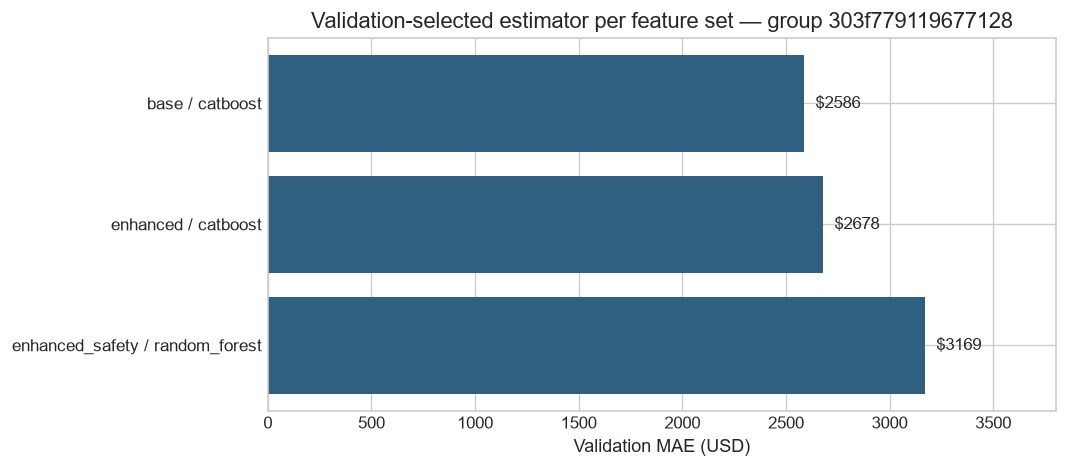

In [3]:
for group, candidates in feature_candidates.groupby("group"):
    comparison_receipt = next((item for item in feature_receipt["comparisons"] if item["group"] == group), None)
    if not comparison_receipt or comparison_receipt["status"] != "completed":
        display(Markdown("Cross-feature ranking unavailable for this provenance bucket: " + str((comparison_receipt or {}).get("reason", "No verified comparison"))))
        continue
    best_features = candidates.sort_values("validation_mae").groupby("variant", sort=False).head(1)
    fig, ax = plt.subplots(figsize=(9, 4))
    labels = best_features.variant + " / " + best_features.model
    ax.barh(labels, best_features.validation_mae, color="#315f80")
    ax.set(xlabel="Validation MAE (USD)", title="Validation-selected estimator per feature set — group " + group)
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], fmt=" $%.0f", padding=4)
    ax.set_xlim(0, best_features.validation_mae.max()*1.2)
    fig.tight_layout()
    plt.show()


,group,left_variant,right_variant,model,doug_source_level,rows,family_blocks,mae_left,rmse_left,mae_right,rmse_right,mae_delta,mae_delta_low,mae_delta_high,rmse_delta,rmse_delta_low,rmse_delta_high,support_status
0,303f779119677128,base,enhanced,catboost,overall,100000,1140,2586.08,7949.96,2677.65,8007.65,91.57,9.30,167.25,57.69,-79.50,178.85,supported
1,303f779119677128,base,enhanced,elastic_net,overall,100000,1140,4257.95,10581.72,4194.83,12039.39,-63.13,-367.39,218.59,1457.67,-432.49,4223.92,supported
2,303f779119677128,base,enhanced,lasso,overall,100000,1140,4323.08,10718.09,4280.73,11993.53,-42.35,-285.17,197.19,1275.44,-382.95,4018.67,supported
3,303f779119677128,base,enhanced,lightgbm,overall,100000,1140,2991.54,8839.50,2990.34,8808.89,-1.20,-92.84,98.68,-30.61,-208.89,97.15,supported
4,303f779119677128,base,enhanced,multiple_linear_regression,overall,100000,1140,3824.58,9577.33,3728.31,12708.95,-96.27,-398.55,328.05,3131.61,-319.19,7454.53,supported
5,303f779119677128,base,enhanced,random_forest,overall,100000,1140,3187.87,8971.93,3247.21,8904.67,59.34,-36.99,147.65,-67.26,-189.69,81.57,supported
6,303f779119677128,base,enhanced,ridge,overall,100000,1140,3818.76,9529.98,3720.95,12104.25,-97.82,-393.44,290.24,2574.27,-238.07,5917.87,supported
7,303f779119677128,base,enhanced,training_median_baseline,overall,100000,1140,11867.22,18687.80,11867.22,18687.80,0.00,0.00,0.00,0.00,0.00,0.00,supported
8,303f779119677128,base,enhanced,xgboost,overall,100000,1140,3152.93,9438.78,3153.86,9445.96,0.93,-75.27,75.15,7.18,-116.09,130.41,supported
9,303f779119677128,enhanced,enhanced_safety,elastic_net,overall,100000,1140,4194.83,12039.39,4095.74,11270.77,-99.09,-264.73,78.48,-768.62,-1603.39,-109.62,supported


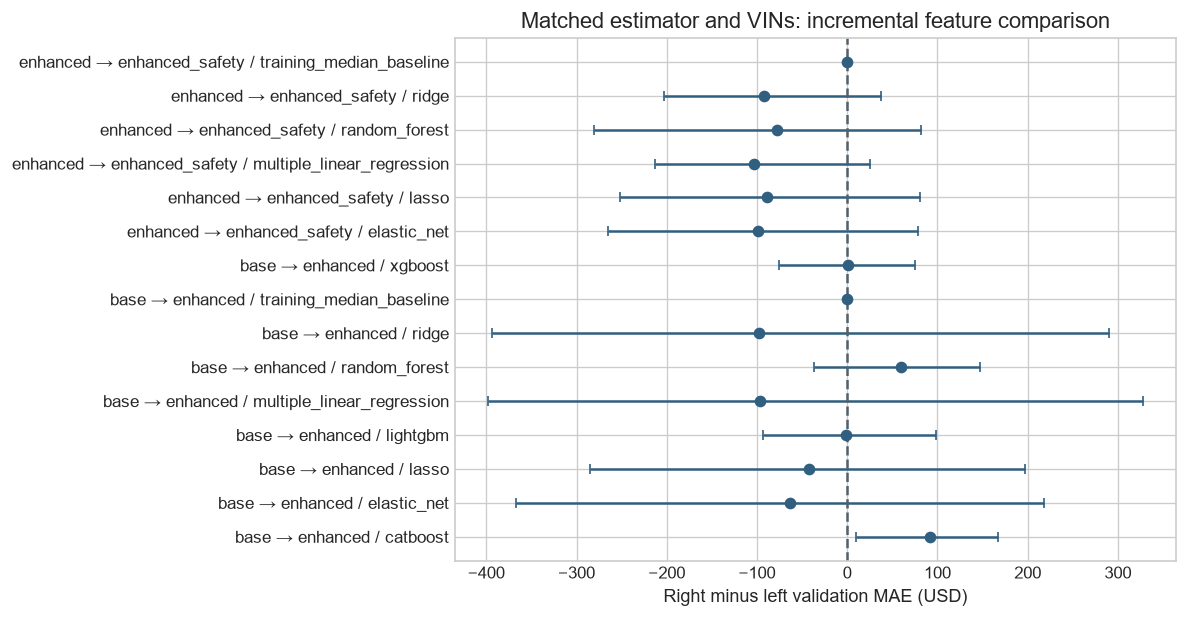

,run,field,value
0,base/20261009T171630407257Z-full,rows_after_filters,2792999
1,base/20261009T171630407257Z-full,listing_rows_without_vpic_match,93
2,enhanced/20261011T050517300002Z-full,rows_after_filters,2792999
3,enhanced/20261011T050517300002Z-full,listing_rows_without_vpic_match,93
4,enhanced_safety/20261017T203431387661Z-full,rows_after_filters,2792999
5,enhanced_safety/20261017T203431387661Z-full,listing_rows_without_vpic_match,93
6,enhanced_safety/20261017T203431387661Z-full,complaint_recall_coverage,"{""complaint_source_records_present"": [{""compla..."


In [4]:
incremental_file = feature_report / "incremental_feature_comparison.csv"
if incremental_file.is_file():
    incremental_features = pd.read_csv(incremental_file)
    display(incremental_features.round(2))
    for group, comparison in incremental_features.groupby("group"):
        comparison = comparison.reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(10, max(4, len(comparison)*.35)))
        labels = comparison.left_variant + " → " + comparison.right_variant + " / " + comparison.model
        ax.errorbar(comparison.mae_delta, np.arange(len(comparison)),
                    xerr=np.vstack([np.maximum(0, comparison.mae_delta-comparison.mae_delta_low),
                                    np.maximum(0, comparison.mae_delta_high-comparison.mae_delta)]),
                    fmt="o", color="#315f80", capsize=3)
        ax.axvline(0, linestyle="--", color="#52606b")
        ax.set(yticks=np.arange(len(labels)), yticklabels=labels, xlabel="Right minus left validation MAE (USD)",
               title="Matched estimator and VINs: incremental feature comparison")
        fig.tight_layout()
        plt.show()
coverage_file = feature_report / "source_coverage.csv"
if coverage_file.is_file():
    display(pd.read_csv(coverage_file))


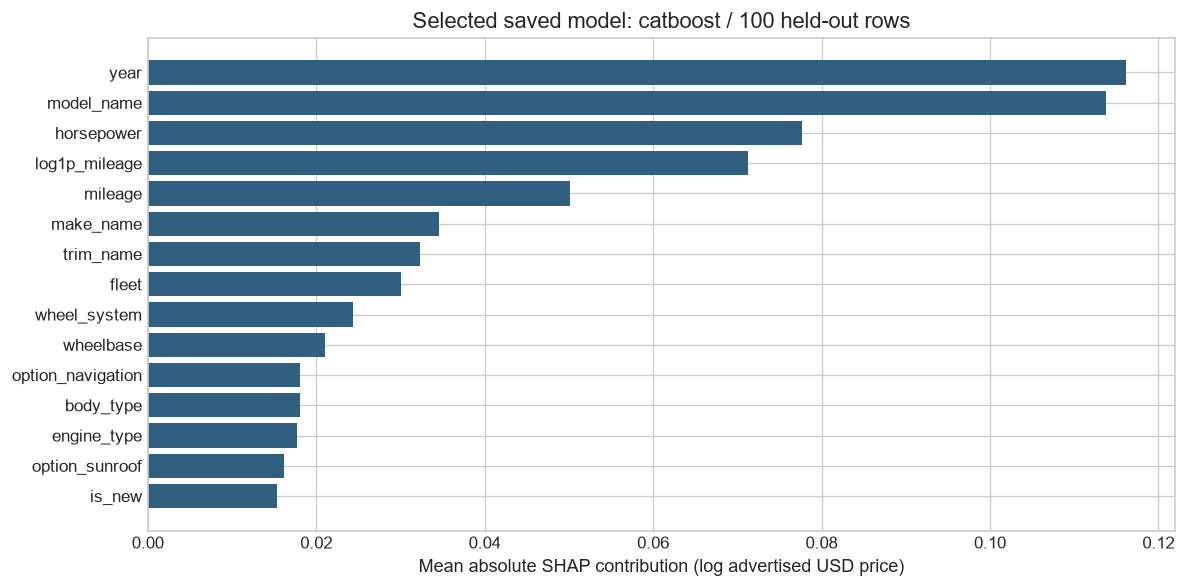

In [5]:
for explanation in feature_receipt.get("explanations", []):
    if explanation.get("status") == "completed":
        explanation_file = Path(explanation["directory"]) / explanation["model"] / explanation["global_importance"]
        importance = pd.read_csv(explanation_file).head(15).sort_values("mean_absolute_shap")
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.barh(importance.feature, importance.mean_absolute_shap, color="#315f80")
        ax.set(xlabel="Mean absolute SHAP contribution (log advertised USD price)",
               title=f"Selected saved model: {explanation['model']} / {explanation['rows']} held-out rows")
        fig.tight_layout()
        plt.show()


## Integration

After training finishes, publish a fresh `car_app.model_registry` comparison and explicitly activate a compatible validation-selected model. Price estimates do not change observed-price eligibility or direct-peer ranking.

## Detailed saved-run diagnostics

Set `RUN_PATH` to pin a run. Automatic combinations require matching samples, features, splits, code, environment, and preprocessing.

In [6]:
model_type_dir = MODEL_OUTPUT_DIR / MODEL_TYPE
run_dirs = sorted(
    [p for p in model_type_dir.iterdir()
     if p.is_dir() and (p / "metrics.csv").is_file()
     and (p / "run_metadata.json").is_file()
     and json.loads((p / "run_metadata.json").read_text(encoding="utf-8")).get("status", "completed") == "completed"],
    key=lambda p: p.name, reverse=True,
) if model_type_dir.is_dir() else []

if RUN_PATH is not None:
    selected_run = Path(RUN_PATH)
    if not selected_run.is_absolute():
        selected_run = PROJECT_ROOT / selected_run
    if not selected_run.is_dir():
        raise FileNotFoundError(f"Run folder not found: {selected_run}")
else:
    selected_run = run_dirs[0] if run_dirs else None

RUN_AVAILABLE = selected_run is not None
selected_runs = [selected_run] if RUN_AVAILABLE else []
if RUN_AVAILABLE:
    # Combine only content-, split-, code-, environment-, and preprocessing-matched runs.
    # Legacy runs without fingerprints remain readable individually.
    primary_metadata = json.loads((selected_run / "run_metadata.json").read_text(encoding="utf-8"))
    if primary_metadata.get("status", "completed") != "completed":
        raise ValueError("Selected run is incomplete or failed; inspect its run_metadata.json")
    combined_model_names = set(primary_metadata.get("models", {}))
    for candidate in run_dirs:
        if candidate == selected_run:
            continue
        candidate_metadata = json.loads((candidate / "run_metadata.json").read_text(encoding="utf-8"))
        candidate_names = set(candidate_metadata.get("models", {}))
        if compatible_run_metadata(primary_metadata, candidate_metadata) and candidate_names.isdisjoint(combined_model_names):
            selected_runs.append(candidate)
            combined_model_names.update(candidate_names)
    print(f"Selected primary run: {selected_run}")
    display(pd.DataFrame({
        "run_folder": [p.name for p in run_dirs],
        "metrics_present": [(p / "metrics.csv").is_file() for p in run_dirs],
        "metadata_present": [(p / "run_metadata.json").is_file() for p in run_dirs],
    }))
else:
    display(Markdown(
        f"No completed run was found under {model_type_dir}. Train a pilot first "
        "with the command in README.md, then rerun this notebook."
    ))

Selected primary run: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\base\20261009T171630407257Z-full


,run_folder,metrics_present,metadata_present
0,20261009T171630407257Z-full,True,True
1,20260930T175441965152Z-pilot-50000,True,True
2,20260930T163252673448Z-pilot-50000,True,True
3,20260930T002248817124Z-pilot-100000,True,True
4,20260929T191725604184Z-pilot-100000,True,True
5,20260928T160910025406Z-pilot-100000,True,True
6,20260928T024221149544Z-pilot-3000,True,True
7,20260928T014950675918Z-pilot-50000,True,True
8,20260928T014540322454Z-pilot-50000,True,True
9,20260928T011856173099Z-pilot-100000,True,True


MAE/RMSE use USD; R² is dimensionless. The training-median baseline is the reference. Small groups have limited support.

In [7]:
if RUN_AVAILABLE:
    run_metadata_list = [
        json.loads((run_path / "run_metadata.json").read_text(encoding="utf-8"))
        for run_path in selected_runs
    ]
    metadata = dict(run_metadata_list[0])
    metadata["models"] = {}
    model_run_dirs = {}
    metric_frames = []
    for run_path, run_metadata in zip(selected_runs, run_metadata_list):
        metadata["models"].update(run_metadata.get("models", {}))
        model_run_dirs.update({name: run_path for name in run_metadata.get("models", {})})
        metric_frames.append(pd.read_csv(run_path / "metrics.csv"))
    metrics = pd.concat(metric_frames, ignore_index=True).drop_duplicates("model", keep="first")
    required = {"model", "mae", "rmse", "r2"}
    if required - set(metrics.columns):
        raise ValueError(f"metrics.csv missing columns: {sorted(required - set(metrics.columns))}")
    metrics = metrics.sort_values("validation_mae", na_position="last").reset_index(drop=True) if "validation_mae" in metrics else metrics
    display(metrics.style.format({"mae": "USD {:,.0f}", "rmse": "USD {:,.0f}", "r2": "{:.4f}", "validation_r2": "{:.4f}", "wape_pct": "{:.1f}%"}))

    summary = {
        "model type": metadata.get("model_type"),
        "target": metadata.get("target_interpretation", metadata.get("target_column")),
        "sample requested": metadata.get("requested_sample_size"),
        "rows after filters": metadata.get("rows_after_filters"),
        "training rows": metadata.get("train_rows"),
        "validation rows": metadata.get("validation_rows_for_early_stopping"),
        "test rows": metadata.get("test_rows"),
        "train / validation / test split groups": (
            f"{metadata.get('train_split_groups', metadata.get('train_cohorts'))} / {metadata.get('validation_split_groups', metadata.get('validation_cohorts'))} / "
            f"{metadata.get('test_split_groups', metadata.get('test_cohorts'))}"
        ),
        "split": metadata.get("split_method"),
        "training price weighting": metadata.get("price_weighting", "none"),
        "imputation": metadata.get("imputation", {}).get("method"),
        "matching runs combined": len(selected_runs),
    }
    display(pd.Series(summary, name="Run setup").to_frame())

    tuning_rows = []
    for model_name, details in metadata.get("models", {}).items():
        tuning_rows.append({
            "model": model_name,
            "validation tuning": details.get(
                "validation_tuning_performed",
                details.get("best_iteration") is not None
                and metadata.get("validation_rows_for_early_stopping", 0) > 0,
            ),
            "validation MAE (USD)": details.get("validation_mae"),
            "validation R²": details.get("validation_r2"),
            "selected parameters": json.dumps(details.get("selected_parameters") or {}, default=str),
            "tree count": details.get("best_iteration"),
        })
    if tuning_rows:
        display(pd.DataFrame(tuning_rows))

,mae,rmse,r2,wape_pct,mean_signed_error,p95_absolute_error,median_absolute_error,p90_absolute_error,negative_prediction_count,macro_split_group_mae,mae_group_bootstrap_low,mae_group_bootstrap_high,model,test_rows,validation_mae,selected_parameters,best_iteration,validation_rmse,validation_r2,validation_wape_pct,validation_mean_signed_error,validation_p95_absolute_error
0,"USD 2,410","USD 8,109",0.8468,8.1%,-76.360981,7119.189512,1487.857031,5163.629021,0,9532.206691,2157.997146,2683.893058,catboost,576422,2586.083682,"{""depth"": 6, ""learning_rate"": 0.05, ""l2_leaf_reg"": 20.0}",10471.000000,7949.962948,0.8164,9.035418,-249.015162,7908.620429
1,"USD 2,727","USD 8,984",0.8120,9.2%,-822.238477,7813.538906,1602.513037,5618.914215,0,10193.210190,2391.111071,3142.619255,lightgbm,576422,2991.539975,"{""num_leaves"": 255, ""learning_rate"": 0.05, ""min_child_samples"": 200}",4210.000000,8839.496068,0.7730,10.452026,-96.333314,9019.717831
2,"USD 2,994","USD 9,544",0.7878,10.1%,-686.443799,8639.933594,1851.754883,6282.670117,0,11123.059734,2687.034894,3421.313208,xgboost,576422,3152.928081,"{""max_depth"": 3, ""learning_rate"": 0.08, ""min_child_weight"": 1, ""subsample"": 0.8, ""colsample_bytree"": 0.8, ""objective"": ""reg:squarederror""}",1965.000000,9438.780910,0.7412,11.015894,-700.188082,9171.683301
3,"USD 3,011","USD 8,976",0.8123,10.2%,-208.885047,9090.171501,1804.855593,6484.975050,0,10413.012473,2654.802362,3419.790228,random_forest,576422,3187.865112,"{""model__max_features"": 0.3, ""model__min_samples_leaf"": 2, ""model__n_estimators"": 200}",nan,8971.930462,0.7662,11.137959,-287.357369,9306.625880
4,"USD 3,838","USD 11,043",0.7159,13.0%,-675.286210,11921.999739,2002.010507,7671.680504,0,12926.614027,3269.081891,4670.494926,ridge,576422,3818.761815,"{""model__alpha"": 1.0}",nan,9529.978936,0.7362,13.342225,-369.075736,11020.947502
5,"USD 4,102","USD 12,090",0.6595,13.9%,-418.145237,12356.837044,2004.914159,8015.817204,0,12774.068010,3342.838101,5131.051717,multiple_linear_regression,576422,3824.580121,{},nan,9577.333295,0.7336,13.362553,-389.864626,11050.857565
6,"USD 4,493","USD 11,830",0.6740,15.2%,-853.287401,13536.754352,2611.614021,9831.764716,0,16434.496500,3985.637720,5213.094721,elastic_net,576422,4257.953401,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}",nan,10581.724058,0.6747,14.876699,-334.049437,12849.082600
7,"USD 4,653","USD 11,995",0.6649,15.7%,-974.893582,14308.490577,2683.454585,10387.849087,0,16531.376018,4109.510038,5388.485702,lasso,576422,4323.082277,"{""model__alpha"": 0.001}",nan,10718.088551,0.6663,15.104251,-484.912974,12947.924515
8,"USD 12,983","USD 20,968",-0.0241,43.9%,-3218.607321,37300.000000,9613.000000,24414.800000,0,26993.734943,11356.318066,14843.995738,training_median_baseline,576422,11867.223410,{},nan,18687.800813,-0.0145,41.462435,-2231.627110,28980.250000


,Run setup
model type,base
target,advertised listing price in USD across all lis...
sample requested,None
rows after filters,2792999
training rows,2216577
validation rows,496219
test rows,576422
train / validation / test split groups,7677 / 1536 / 1920
split,year/make/model blocks; all trims together
training price weighting,none


,model,validation tuning,validation MAE (USD),validation R²,selected parameters,tree count
0,catboost,True,2586.083682,0.816409,"{""depth"": 6, ""learning_rate"": 0.05, ""l2_leaf_r...",10471.0
1,lightgbm,True,2991.539975,0.773026,"{""num_leaves"": 255, ""learning_rate"": 0.05, ""mi...",4210.0
2,xgboost,True,3152.928081,0.741207,"{""max_depth"": 3, ""learning_rate"": 0.08, ""min_c...",1965.0
3,random_forest,True,3187.865112,0.766174,"{""model__max_features"": 0.3, ""model__min_sampl...",NaN
4,multiple_linear_regression,True,3824.580121,0.733553,{},NaN
5,lasso,True,4323.082277,0.666300,"{""model__alpha"": 0.001}",NaN
6,ridge,True,3818.761815,0.736182,"{""model__alpha"": 1.0}",NaN
7,elastic_net,True,4257.953401,0.674737,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}",NaN


### Held-out scores

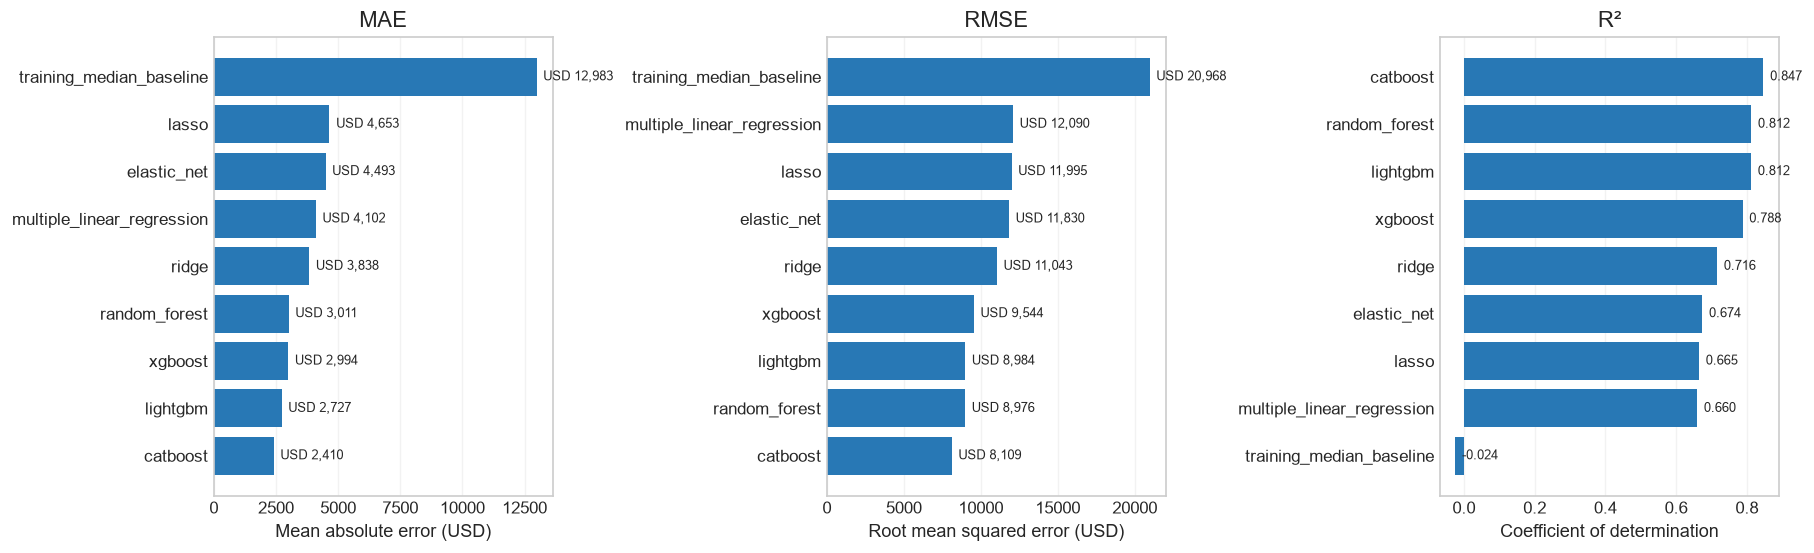

In [8]:
if RUN_AVAILABLE:
    plot_metrics = metrics.set_index("model")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    panels = [
        ("mae", "MAE", "Mean absolute error (USD)", "USD {:,.0f}"),
        ("rmse", "RMSE", "Root mean squared error (USD)", "USD {:,.0f}"),
        ("r2", "R²", "Coefficient of determination", "{:.3f}"),
    ]
    for axis, (column, title, label, fmt) in zip(axes, panels):
        values = plot_metrics[column].sort_values()
        bars = axis.barh(values.index, values.values, color="#2878B5")
        axis.set_title(title)
        axis.set_xlabel(label)
        axis.grid(axis="x", alpha=0.25)
        axis.grid(axis="y", visible=False)
        for bar, value in zip(bars, values.values):
            axis.annotate(fmt.format(value), (bar.get_width(), bar.get_y()+bar.get_height()/2),
                          xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    plt.show()

### Saved models and explanations

In [9]:
if RUN_AVAILABLE:
    inventory = []
    for model_name, details in metadata.get("models", {}).items():
        model_file = model_run_dirs[model_name] / model_name / details.get("model_file", "")
        shap_files = details.get("shap_files") or {}
        inventory.append({
            "model": model_name,
            "saved model": str(model_file.relative_to(model_run_dirs[model_name])) if model_file.is_file() else "missing",
            "global SHAP": shap_files.get("global_importance", "not saved"),
            "row SHAP": shap_files.get("row_values", "not saved"),
            "best iteration": details.get("best_iteration"),
            "selected parameters": json.dumps(details.get("selected_parameters") or {}, default=str),
        })
    display(pd.DataFrame(inventory))

,model,saved model,global SHAP,row SHAP,best iteration,selected parameters
0,catboost,catboost\model.cbm,not saved,not saved,10471.0,"{""depth"": 6, ""learning_rate"": 0.05, ""l2_leaf_r..."
1,lightgbm,lightgbm\model.joblib,not saved,not saved,4210.0,"{""num_leaves"": 255, ""learning_rate"": 0.05, ""mi..."
2,xgboost,xgboost\model.json,not saved,not saved,1965.0,"{""max_depth"": 3, ""learning_rate"": 0.08, ""min_c..."
3,random_forest,random_forest\model.joblib,not saved,not saved,NaN,"{""model__max_features"": 0.3, ""model__min_sampl..."
4,multiple_linear_regression,multiple_linear_regression\model.joblib,not saved,not saved,NaN,{}
5,lasso,lasso\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 0.001}"
6,ridge,ridge\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 1.0}"
7,elastic_net,elastic_net\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}"


## Forest and regression interpretation

Impurity importance can favor continuous/high-cardinality fields. Coefficients apply to fitted transformed inputs; correlated predictors and full one-hot encoding complicate interpretation. These are model diagnostics, not causal effects.

elastic_net: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.425466
1,elastic_net,Coefficient (USD per encoded unit),mileage,numeric__mileage,-0.266524
2,elastic_net,Coefficient (USD per encoded unit),horsepower,numeric__horsepower,0.248166
3,elastic_net,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Wrangler Unlimited,0.234978
4,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Lexus,0.184388
5,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Mercedes-Benz,0.175018
6,elastic_net,Coefficient (USD per encoded unit),fuel_type,categorical__fuel_type_value:Diesel,0.170846
7,elastic_net,Coefficient (USD per encoded unit),body_type,categorical__body_type_value:Convertible,0.155976
8,elastic_net,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V6 Flex Fuel Ve...,-0.147512
9,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Dodge,-0.129093


lasso: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.364506
1,lasso,Coefficient (USD per encoded unit),mileage,numeric__mileage,-0.268559
2,lasso,Coefficient (USD per encoded unit),horsepower,numeric__horsepower,0.254520
3,lasso,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Wrangler Unlimited,0.189335
4,lasso,Coefficient (USD per encoded unit),fuel_type,categorical__fuel_type_value:Diesel,0.175978
5,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Mercedes-Benz,0.158242
6,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Lexus,0.157423
7,lasso,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V6 Flex Fuel Ve...,-0.133510
8,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ford,-0.110177
9,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Dodge,-0.107022


multiple_linear_regression: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Bel Air,2.136143
1,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Deluxe,2.116042
2,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Model A,2.081994
3,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Defender,1.980377
4,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Coupe,1.938871
5,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:X-TYPE,-1.909779
6,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:NSX,1.826643
7,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Levante,1.712848
8,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Century,-1.659749
9,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Chevelle,1.604771


random_forest: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,random_forest,Impurity importance,year,numeric__year,0.195068
1,random_forest,Impurity importance,horsepower,numeric__horsepower,0.153003
2,random_forest,Impurity importance,mileage,numeric__mileage,0.126299
3,random_forest,Impurity importance,log1p_mileage,numeric__log1p_mileage,0.119034
4,random_forest,Impurity importance,width,numeric__width,0.049863
5,random_forest,Impurity importance,wheel_system,categorical__wheel_system_value:FWD,0.039646
6,random_forest,Impurity importance,engine_displacement,numeric__engine_displacement,0.032101
7,random_forest,Impurity importance,owner_count__missing,numeric__owner_count__missing,0.031530
8,random_forest,Impurity importance,wheelbase,numeric__wheelbase,0.025476
9,random_forest,Impurity importance,is_new,categorical__is_new_value:True,0.018826


ridge: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Bel Air,2.626217
1,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Chevelle,2.129149
2,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Model A,1.844171
3,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Bronco,1.732876
4,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Deluxe,1.483400
5,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Nova,1.424345
6,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ferrari,1.297222
7,ridge,Coefficient (USD per encoded unit),trim_name,categorical__trim_name_value:SS,1.263418
8,ridge,Coefficient (USD per encoded unit),trim_name,categorical__trim_name_value:Pickup,1.222406
9,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:NSX,1.220721


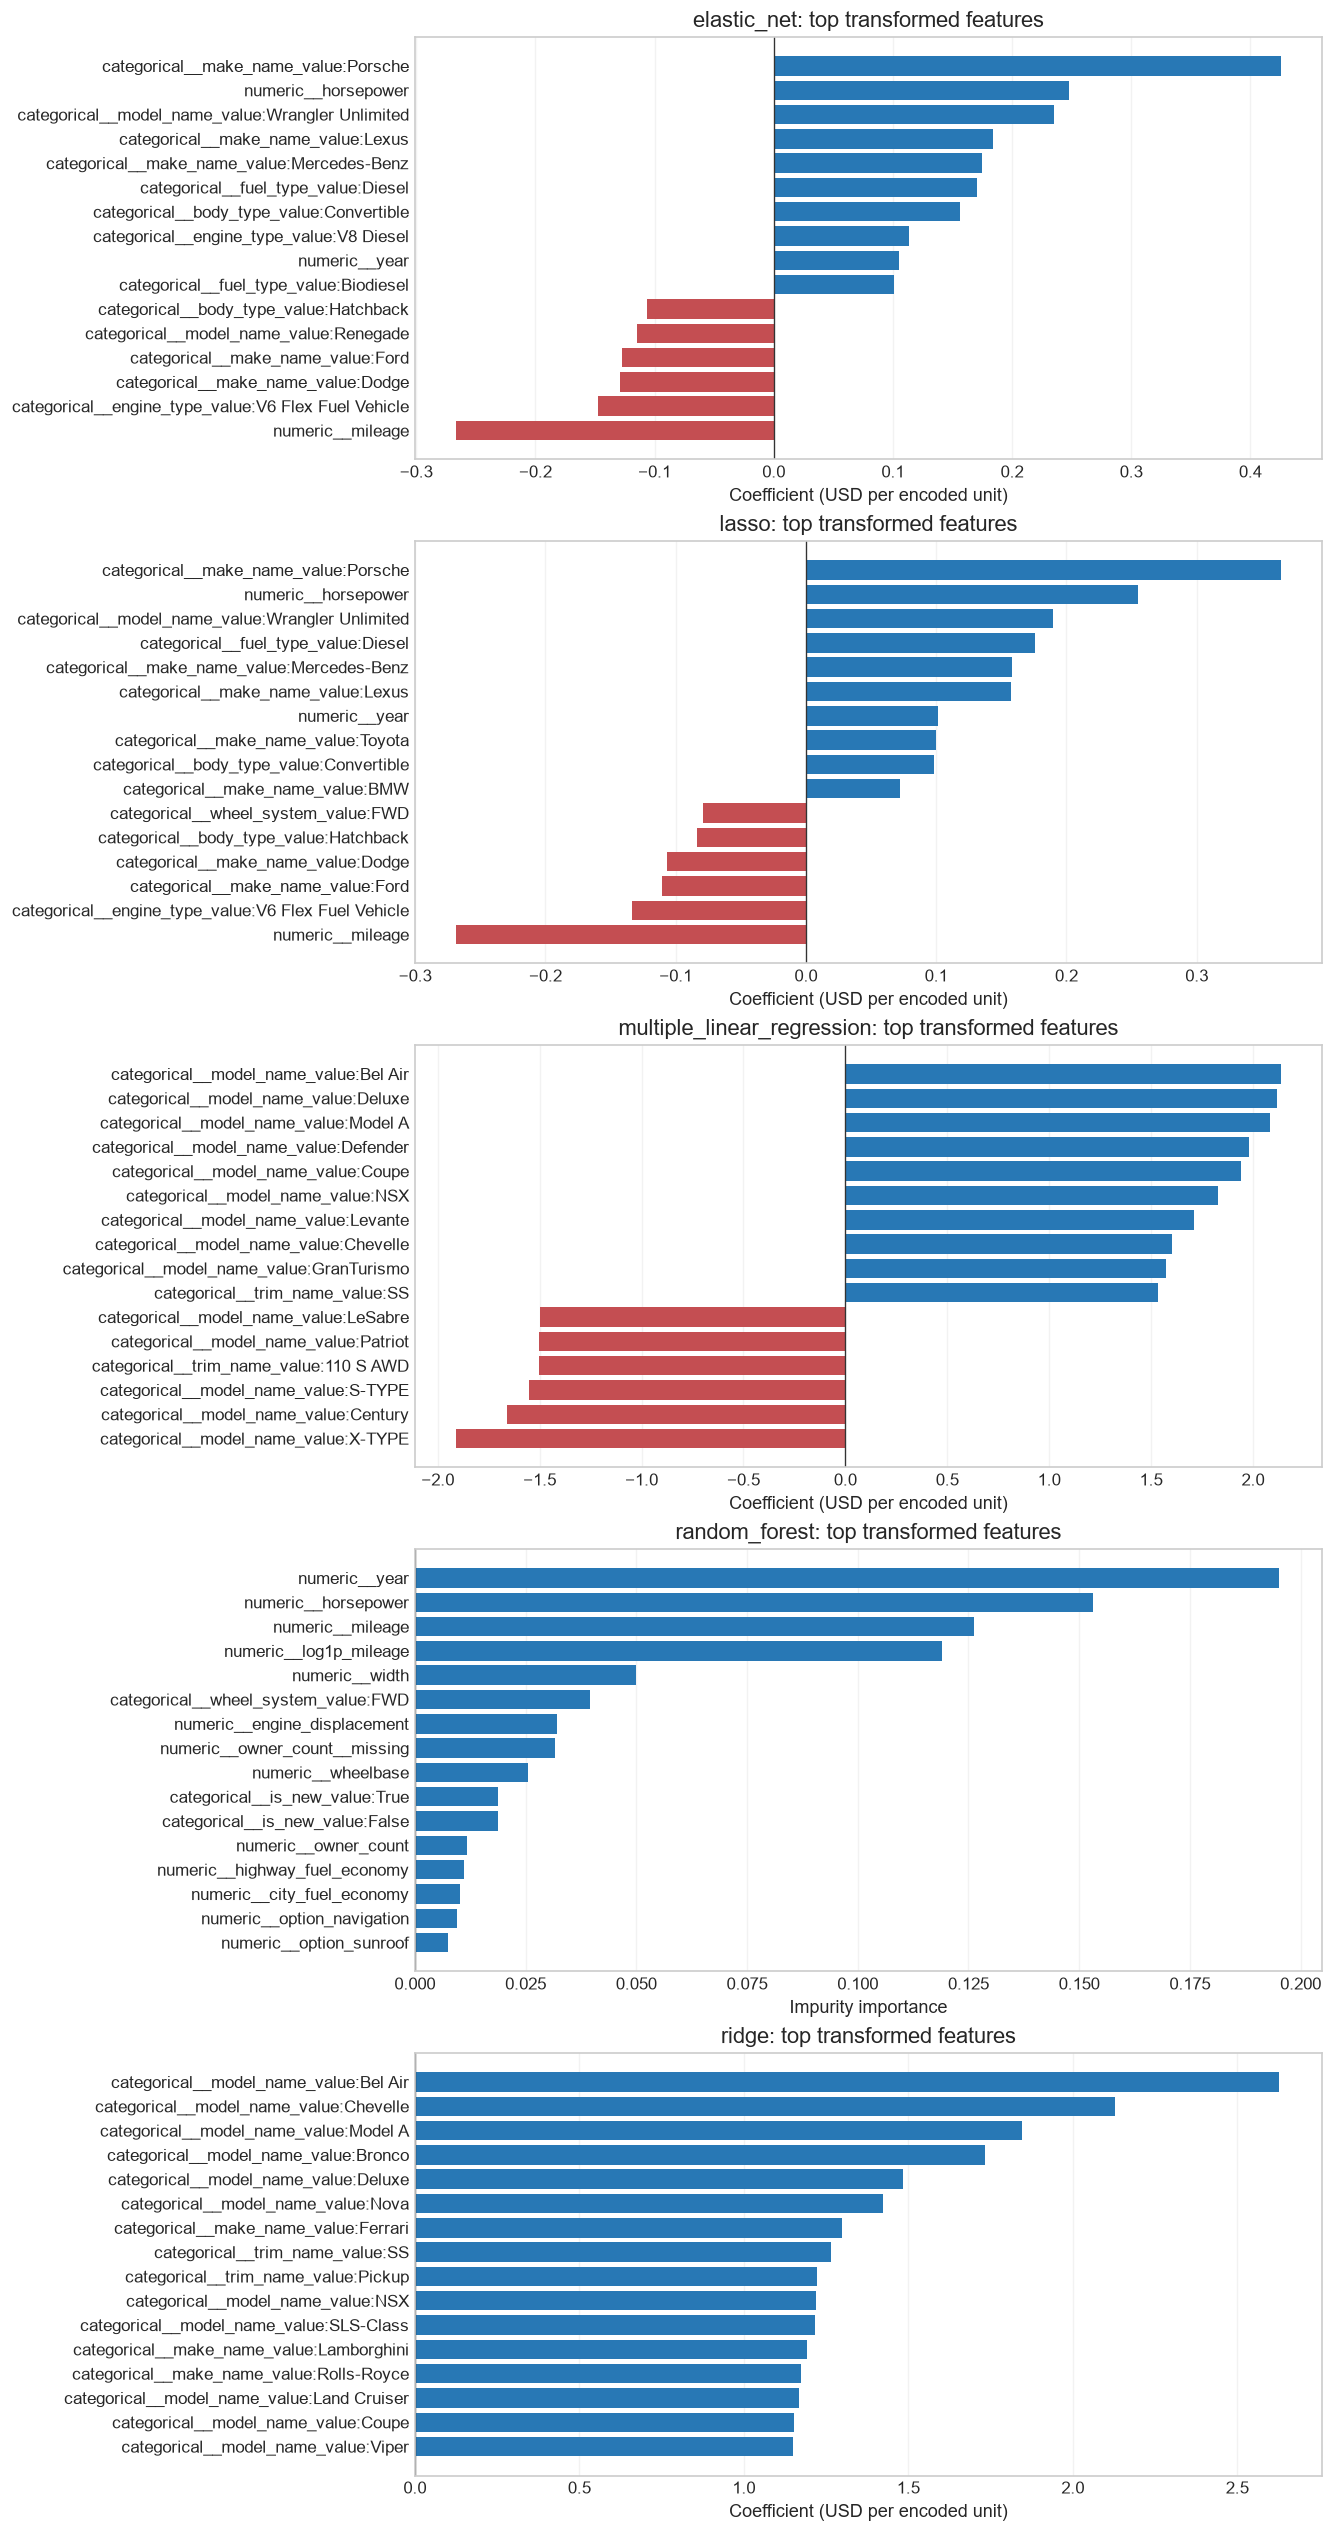

In [10]:
if RUN_AVAILABLE:
    classical_names = {
        "random_forest", "multiple_linear_regression", "lasso", "ridge", "elastic_net"
    }
    interpretation_rows = []
    interpretation_models = []
    categorical_features = metadata.get("categorical_features", [])

    def source_feature_for_term(term):
        if term.startswith("numeric__"):
            return term.removeprefix("numeric__")
        encoded = term.removeprefix("categorical__")
        matches = [name for name in categorical_features
                   if encoded == name or encoded.startswith(name + "_")]
        return max(matches, key=len) if matches else encoded

    for model_name in sorted(classical_names & set(metadata.get("models", {}))):
        details = metadata["models"][model_name]
        model_path = model_run_dirs[model_name] / model_name / details.get("model_file", "")
        if not model_path.is_file() or model_path.suffix != ".joblib":
            continue
        import joblib
        pipeline = joblib.load(model_path)
        model = pipeline.named_steps["model"]
        terms = pipeline.named_steps["preprocess"].get_feature_names_out()
        if model_name == "random_forest":
            values = model.feature_importances_
            kind = "Impurity importance"
        else:
            values = model.coef_
            kind = "Coefficient (USD per encoded unit)"
        if len(terms) != len(values):
            raise ValueError(f"Transformed feature count does not match {model_name} parameters")
        frame = pd.DataFrame({
            "model": model_name,
            "interpretation": kind,
            "source feature": [source_feature_for_term(term) for term in terms],
            "encoded term": terms,
            "value": values,
        })
        frame["absolute value"] = frame["value"].abs()
        interpretation_rows.append(frame)
        interpretation_models.append((model_name, frame))

    if not interpretation_rows:
        display(Markdown(
            "No Random Forest or regression model artifacts are present in this run. "
            "Run the updated Price_ML_Models.py pilot with those model names, then select "
            "that completed run here."
        ))
    else:
        interpretations = pd.concat(interpretation_rows, ignore_index=True)
        for model_name, frame in interpretation_models:
            print(f"{model_name}: largest encoded terms by absolute value")
            display(frame.nlargest(20, "absolute value").drop(columns="absolute value")
                    .reset_index(drop=True))

        fig, axes = plt.subplots(len(interpretation_models), 1,
                                 figsize=(11, 4.2 * len(interpretation_models)),
                                 squeeze=False, constrained_layout=True)
        for axis, (model_name, frame) in zip(axes[:, 0], interpretation_models):
            top = frame.nlargest(16, "absolute value").sort_values("value")
            colors = ["#C44E52" if value < 0 else "#2878B5" for value in top["value"]]
            axis.barh(top["encoded term"], top["value"], color=colors)
            axis.axvline(0, color="#333333", linewidth=0.8)
            axis.set_title(f"{model_name}: top transformed features")
            axis.set_xlabel("Impurity importance" if model_name == "random_forest"
                            else "Coefficient (USD per encoded unit)")
            axis.set_ylabel("")
            axis.grid(axis="x", alpha=0.25)
            axis.grid(axis="y", visible=False)
        plt.show()

## Global SHAP

Mean absolute attribution uses natural-log price on a bounded held-out sample; it is not causal importance.

In [11]:
if RUN_AVAILABLE:
    global_paths = sorted({path for run_path in selected_runs
                           for path in run_path.glob("*/*_shap_global.csv")})
    frames = []
    for path in global_paths:
        values = pd.read_csv(path)
        if {"feature", "mean_absolute_shap"} <= set(values.columns):
            values["model"] = path.name.removesuffix("_shap_global.csv")
            frames.append(values)
    if not frames:
        display(Markdown("No global SHAP files were found for this run."))
    else:
        shap_global = pd.concat(frames, ignore_index=True)
        shap_models = shap_global["model"].unique().tolist()
        fig, axes = plt.subplots(1, len(shap_models), figsize=(6*len(shap_models), 7),
                                 squeeze=False, constrained_layout=True)
        for axis, model_name in zip(axes[0], shap_models):
            top = (shap_global[shap_global["model"] == model_name]
                   .nlargest(20, "mean_absolute_shap").sort_values("mean_absolute_shap"))
            axis.barh(top["feature"], top["mean_absolute_shap"], color="#2878B5")
            axis.set_title(f"{model_name}: top features")
            axis.set_xlabel("Mean absolute SHAP value (ln USD)")
            axis.set_ylabel("")
        plt.show()
        display(shap_global.sort_values(
            ["model", "mean_absolute_shap"], ascending=[True, False]
        ).groupby("model").head(10).reset_index(drop=True))

No global SHAP files were found for this run.

### Row-level SHAP

Signed contributions and the baseline use natural-log price.

In [12]:
if RUN_AVAILABLE:
    row_shap_paths = sorted({path for run_path in selected_runs
                              for path in run_path.glob("*/*_shap_values.parquet")})
    if not row_shap_paths:
        display(Markdown("No row-level SHAP files were found for this run."))
    else:
        row_path = row_shap_paths[0]
        row_shap = pd.read_parquet(row_path)
        required = {"test_row", "actual_price", "actual_log_price", "predicted_log_price", "base_value_log_price"}
        if required - set(row_shap.columns):
            raise ValueError(f"SHAP file missing columns: {sorted(required - set(row_shap.columns))}")
        row_index = min(max(int(SHAP_ROW), 0), len(row_shap) - 1)
        explanation = row_shap.iloc[row_index]
        features = [c for c in metadata.get("feature_columns", []) if c in row_shap.columns]
        contributions = explanation[features].astype(float)
        top = contributions.loc[
            contributions.abs().nlargest(min(15, len(contributions))).index
        ].sort_values()
        colors = ["#C44E52" if value < 0 else "#2878B5" for value in top.values]
        print(f"Model: {row_path.parent.name}; sample row: {row_index}; "
              f"actual=USD {explanation['actual_price']:,.0f}; "
              f"prediction=USD {np.exp(explanation['predicted_log_price']):,.0f}")
        reconstructed_log = float(explanation["base_value_log_price"] + contributions.sum())
        fig, axis = plt.subplots(figsize=(9, 6), constrained_layout=True)
        axis.barh(top.index, top.values, color=colors)
        axis.axvline(0, color="#333333", linewidth=0.8)
        axis.set_title("Largest signed SHAP contributions for one test row")
        axis.set_xlabel("Contribution to ln(listed price in USD)")
        axis.set_ylabel("")
        plt.show()
        display(row_shap.iloc[[row_index]])

No row-level SHAP files were found for this run.

### Prediction diagnostics

The scatter is sampled; residual distributions use all held-out predictions.

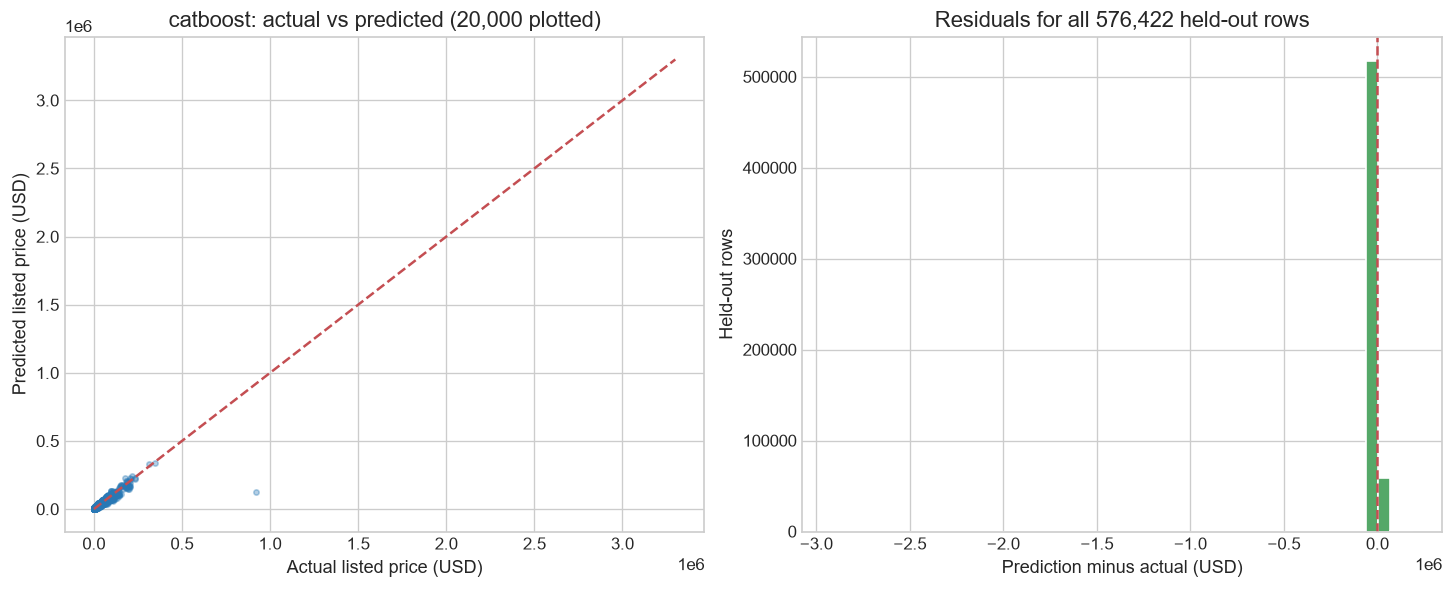

In [13]:
if RUN_AVAILABLE:
    ranked = (metrics[(metrics.model != "training_median_baseline") & metrics.validation_mae.notna()]
              if "validation_mae" in metrics else pd.DataFrame())
    diagnostic_model = ranked.sort_values("validation_mae").iloc[0]["model"] if not ranked.empty else None
    if diagnostic_model is None and not metrics.empty:
        diagnostic_model = metrics.iloc[0]["model"]
    prediction_path = (model_run_dirs[diagnostic_model] / f"{diagnostic_model}_test_predictions.parquet"
                       if diagnostic_model is not None else None)
    if prediction_path is None or not prediction_path.is_file():
        display(Markdown("No full held-out prediction file is available for residual diagnostics."))
    else:
        diagnostics = pd.read_parquet(prediction_path)
        plot_rows = diagnostics.sample(min(20000, len(diagnostics)), random_state=42) if len(diagnostics) > 20000 else diagnostics
        residual = diagnostics["prediction"] - diagnostics["actual_price"]
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
        axes[0].scatter(plot_rows["actual_price"], plot_rows["prediction"],
                        s=10, alpha=0.35, color="#2878B5")
        lower = min(diagnostics["actual_price"].min(), diagnostics["prediction"].min())
        upper = max(diagnostics["actual_price"].max(), diagnostics["prediction"].max())
        axes[0].plot([lower, upper], [lower, upper], "--", color="#C44E52")
        axes[0].set_title(f"{diagnostic_model}: actual vs predicted ({len(plot_rows):,} plotted)")
        axes[0].set_xlabel("Actual listed price (USD)")
        axes[0].set_ylabel("Predicted listed price (USD)")
        axes[1].hist(residual, bins=50, color="#55A868", edgecolor="white")
        axes[1].axvline(0, linestyle="--", color="#C44E52")
        axes[1].set_title(f"Residuals for all {len(diagnostics):,} held-out rows")
        axes[1].set_xlabel("Prediction minus actual (USD)")
        axes[1].set_ylabel("Held-out rows")
        plt.show()


## Run summary

In [14]:
if RUN_AVAILABLE:
    ranked = (metrics[(metrics.model != "training_median_baseline") & metrics.validation_mae.notna()]
              if "validation_mae" in metrics else pd.DataFrame())
    if ranked.empty:
        display(Markdown("No validation selection is available for this legacy run. Test scores are descriptive only."))
    else:
        chosen = ranked.sort_values("validation_mae").iloc[0]
    segment_frames = [pd.read_csv(p / "segment_metrics.csv") for p in selected_runs if (p / "segment_metrics.csv").is_file()]
    if segment_frames:
        display(pd.concat(segment_frames, ignore_index=True).drop_duplicates(["model", "dimension", "segment"]))
    else:
        display(Markdown("This legacy run has no saved segment metrics."))
    year_make_frames = [pd.read_csv(p / "year_make_metrics.csv") for p in selected_runs
                        if (p / "year_make_metrics.csv").is_file()]
    if year_make_frames:
        year_make = pd.concat(year_make_frames, ignore_index=True)
        selected_model = metadata.get("selected_by_validation_mae")
        if selected_model in set(year_make["model"]):
            year_make = year_make[year_make["model"] == selected_model]
        formats = {"median_actual_price": "USD {:,.0f}", "mae_usd": "USD {:,.0f}",
            "rmse_usd": "USD {:,.0f}", "mean_signed_error_usd": "USD {:,.0f}",
            "p90_absolute_error_usd": "USD {:,.0f}", "wape_pct": "{:.1f}%",
            "mae_pct_of_median_price": "{:.1f}%", "rows": "{:,.0f}",
            "family_blocks": "{:,.0f}", "r2": "{:.4f}"}
        display(Markdown("**By model year**"))
        display(year_make[year_make.metric_level == "year"].sort_values("ModelYear").style.format(formats, na_rep="—"))
        display(Markdown("**By make**"))
        display(year_make[year_make.metric_level == "make"].sort_values("Make", na_position="last").style.format(formats, na_rep="—"))
        year_make_pairs = year_make[(year_make.metric_level == "year_make") & (year_make.support_status == "supported")]
        display(Markdown("**Supported year/make groups with the most test listings (up to 100)**"))
        display(year_make_pairs.nlargest(100, "rows").sort_values(["ModelYear", "Make"], na_position="last").style.format(formats, na_rep="—"))
    else:
        display(Markdown("No year/make metrics are available for this legacy run."))
else:
    display(Markdown("No completed run is selected."))


,model,dimension,segment,rows,family_blocks,median_actual_price,mae,rmse,r2,wape_pct,mean_signed_error,p95_absolute_error,support_status,price_band_lower_usd,price_band_upper_usd
0,training_median_baseline,is_new,False,299684,1897,18987.0,11311.885236,19210.424735,-0.055654,51.560355,4410.885703,22352.000000,supported,NaN,NaN
1,training_median_baseline,is_new,True,276738,231,33901.0,14793.466737,22717.812816,-0.342985,39.104389,-11480.707167,47030.000000,supported,NaN,NaN
2,training_median_baseline,cohort_complete,False,110710,1119,25110.0,13773.556147,27704.405265,-0.010073,47.304756,-2766.641216,34708.100000,supported,NaN,NaN
3,training_median_baseline,cohort_complete,True,465712,1002,24612.0,12795.536752,19018.298760,-0.031550,43.117386,-3326.049619,37675.000000,supported,NaN,NaN
4,training_median_baseline,split_identity_source,listing_identity_fallback,638,301,29900.0,35123.631661,84451.069891,-0.103236,67.307732,-25833.650470,130845.750000,supported,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1786,elastic_net,Make,VOLVO,1173,37,35795.0,4747.195591,6378.781996,0.873461,17.075269,-1931.821954,12944.438986,supported,NaN,NaN
1787,elastic_net,Make,VOLVO TRUCK,1,1,12995.0,2142.784782,2142.784782,NaN,16.489302,-2142.784782,2142.784782,low_support,NaN,NaN
1788,elastic_net,Make,"WOOD-MIZER PRODUCTS, INC.",1,1,29900.0,19652.393809,19652.393809,NaN,65.727070,-19652.393809,19652.393809,low_support,NaN,NaN
1789,elastic_net,Make,WORTHINGTON TRAILER L.P.,1,1,4000.0,139.421103,139.421103,NaN,3.485528,-139.421103,139.421103,low_support,NaN,NaN


**By model year**

,model,metric_level,ModelYear,Make,r2,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
0,training_median_baseline,year,1980.000000,—,—,1,1,"USD 15,000","USD 11,350","USD 11,350","USD 11,350","USD 11,350",75.7%,75.7%,low_support
1015,catboost,year,1980.000000,—,—,1,1,"USD 15,000","USD 3,672","USD 3,672","USD 3,672","USD 3,672",24.5%,24.5%,low_support
6090,lasso,year,1980.000000,—,—,1,1,"USD 15,000","USD 4,368","USD 4,368","USD -4,368","USD 4,368",29.1%,29.1%,low_support
8120,elastic_net,year,1980.000000,—,—,1,1,"USD 15,000","USD 4,633","USD 4,633","USD -4,633","USD 4,633",30.9%,30.9%,low_support
2030,lightgbm,year,1980.000000,—,—,1,1,"USD 15,000","USD 8,371","USD 8,371","USD 8,371","USD 8,371",55.8%,55.8%,low_support
4060,random_forest,year,1980.000000,—,—,1,1,"USD 15,000","USD 3,800","USD 3,800","USD 3,800","USD 3,800",25.3%,25.3%,low_support
3045,xgboost,year,1980.000000,—,—,1,1,"USD 15,000","USD 12,189","USD 12,189","USD 12,189","USD 12,189",81.3%,81.3%,low_support
7105,ridge,year,1980.000000,—,—,1,1,"USD 15,000","USD 2,486","USD 2,486","USD -2,486","USD 2,486",16.6%,16.6%,low_support
5075,multiple_linear_regression,year,1980.000000,—,—,1,1,"USD 15,000","USD 1,525","USD 1,525","USD -1,525","USD 1,525",10.2%,10.2%,low_support
2031,lightgbm,year,1981.000000,—,0.5279,10,6,"USD 8,748","USD 8,245","USD 13,386","USD 5,819","USD 13,248",45.7%,94.2%,low_support


**By make**

,model,metric_level,ModelYear,Make,r2,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
43,training_median_baseline,make,—,ACURA,-0.0190,"5,033",30,"USD 29,199","USD 9,084","USD 11,316","USD -1,546","USD 17,874",32.6%,31.1%,supported
1058,catboost,make,—,ACURA,0.9007,"5,033",30,"USD 29,199","USD 2,218","USD 3,532",USD 580,"USD 5,420",8.0%,7.6%,supported
2073,lightgbm,make,—,ACURA,0.8803,"5,033",30,"USD 29,199","USD 2,164","USD 3,879","USD -1,475","USD 4,581",7.8%,7.4%,supported
3088,xgboost,make,—,ACURA,0.9576,"5,033",30,"USD 29,199","USD 1,408","USD 2,309",USD 36,"USD 2,878",5.0%,4.8%,supported
4103,random_forest,make,—,ACURA,0.9089,"5,033",30,"USD 29,199","USD 2,100","USD 3,383","USD -1,682","USD 3,898",7.5%,7.2%,supported
5118,multiple_linear_regression,make,—,ACURA,0.8893,"5,033",30,"USD 29,199","USD 2,751","USD 3,730","USD -1,461","USD 5,076",9.9%,9.4%,supported
6133,lasso,make,—,ACURA,0.7181,"5,033",30,"USD 29,199","USD 4,240","USD 5,952","USD -3,011","USD 8,434",15.2%,14.5%,supported
7148,ridge,make,—,ACURA,0.8831,"5,033",30,"USD 29,199","USD 2,749","USD 3,833","USD -1,413","USD 5,123",9.9%,9.4%,supported
8163,elastic_net,make,—,ACURA,0.7213,"5,033",30,"USD 29,199","USD 4,186","USD 5,918","USD -2,978","USD 8,295",15.0%,14.3%,supported
44,training_median_baseline,make,—,ALFA ROMEO,-1.6931,"2,315",7,"USD 39,295","USD 13,155","USD 16,308","USD -12,931","USD 24,695",33.5%,33.5%,supported


**Supported year/make groups with the most test listings (up to 100)**

,model,metric_level,ModelYear,Make,r2,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
834,training_median_baseline,year_make,2016.000000,CHEVROLET,-0.0463,"3,289",7,"USD 20,800","USD 8,959","USD 12,197","USD 2,565","USD 17,355",37.7%,43.1%,supported
864,training_median_baseline,year_make,2017.000000,CHEVROLET,-2.1126,"7,700",5,"USD 15,996","USD 9,727","USD 10,390","USD 8,560","USD 13,373",54.7%,60.8%,supported
1879,catboost,year_make,2017.000000,CHEVROLET,0.9045,"7,700",5,"USD 15,996","USD 1,252","USD 1,820",USD -237,"USD 2,656",7.0%,7.8%,supported
2894,lightgbm,year_make,2017.000000,CHEVROLET,0.9025,"7,700",5,"USD 15,996","USD 1,266","USD 1,838",USD -91,"USD 2,704",7.1%,7.9%,supported
3909,xgboost,year_make,2017.000000,CHEVROLET,0.8029,"7,700",5,"USD 15,996","USD 1,824","USD 2,614",USD 456,"USD 4,229",10.3%,11.4%,supported
4924,random_forest,year_make,2017.000000,CHEVROLET,0.8428,"7,700",5,"USD 15,996","USD 1,647","USD 2,335",USD 107,"USD 3,741",9.3%,10.3%,supported
5939,multiple_linear_regression,year_make,2017.000000,CHEVROLET,0.8319,"7,700",5,"USD 15,996","USD 1,676","USD 2,415",USD 162,"USD 3,764",9.4%,10.5%,supported
6954,lasso,year_make,2017.000000,CHEVROLET,0.4120,"7,700",5,"USD 15,996","USD 3,097","USD 4,516","USD 2,456","USD 7,936",17.4%,19.4%,supported
7969,ridge,year_make,2017.000000,CHEVROLET,0.8464,"7,700",5,"USD 15,996","USD 1,622","USD 2,308",USD 83,"USD 3,573",9.1%,10.1%,supported
8984,elastic_net,year_make,2017.000000,CHEVROLET,0.5120,"7,700",5,"USD 15,996","USD 2,808","USD 4,114","USD 2,046","USD 7,132",15.8%,17.6%,supported


## Feature-set comparison

Paired comparisons require compatible fingerprints and identical held-out VINs/targets. Intervals resample family split blocks. Enrichment timing remains retrospective. Set `RUN_PATHS` to pin runs.

,eligible listings,test listings,test split groups,predictors,selected ML model,validation MAE (USD),ML test MAE (USD),ML test RMSE (USD),ML test R²,ML validation R²,training weighting,median-baseline test MAE (USD)
feature set,,,,,,,,,,,,
base,"2,792,999","576,422",1920,39,catboost,"USD 2,586",2409.523708,8109.454848,0.8468,0.8164,none,12983.379213
enhanced,"2,792,999","576,422",1920,93,catboost,"USD 2,678",2604.963475,8440.490570,0.8340,0.8137,none,12983.379213
enhanced_safety,"2,792,999","576,422",1920,113,random_forest,"USD 3,169",3066.218874,8834.559705,0.8182,0.7788,none,12983.379213


Source-specific feature-set ablations have been consolidated into `enriched`.

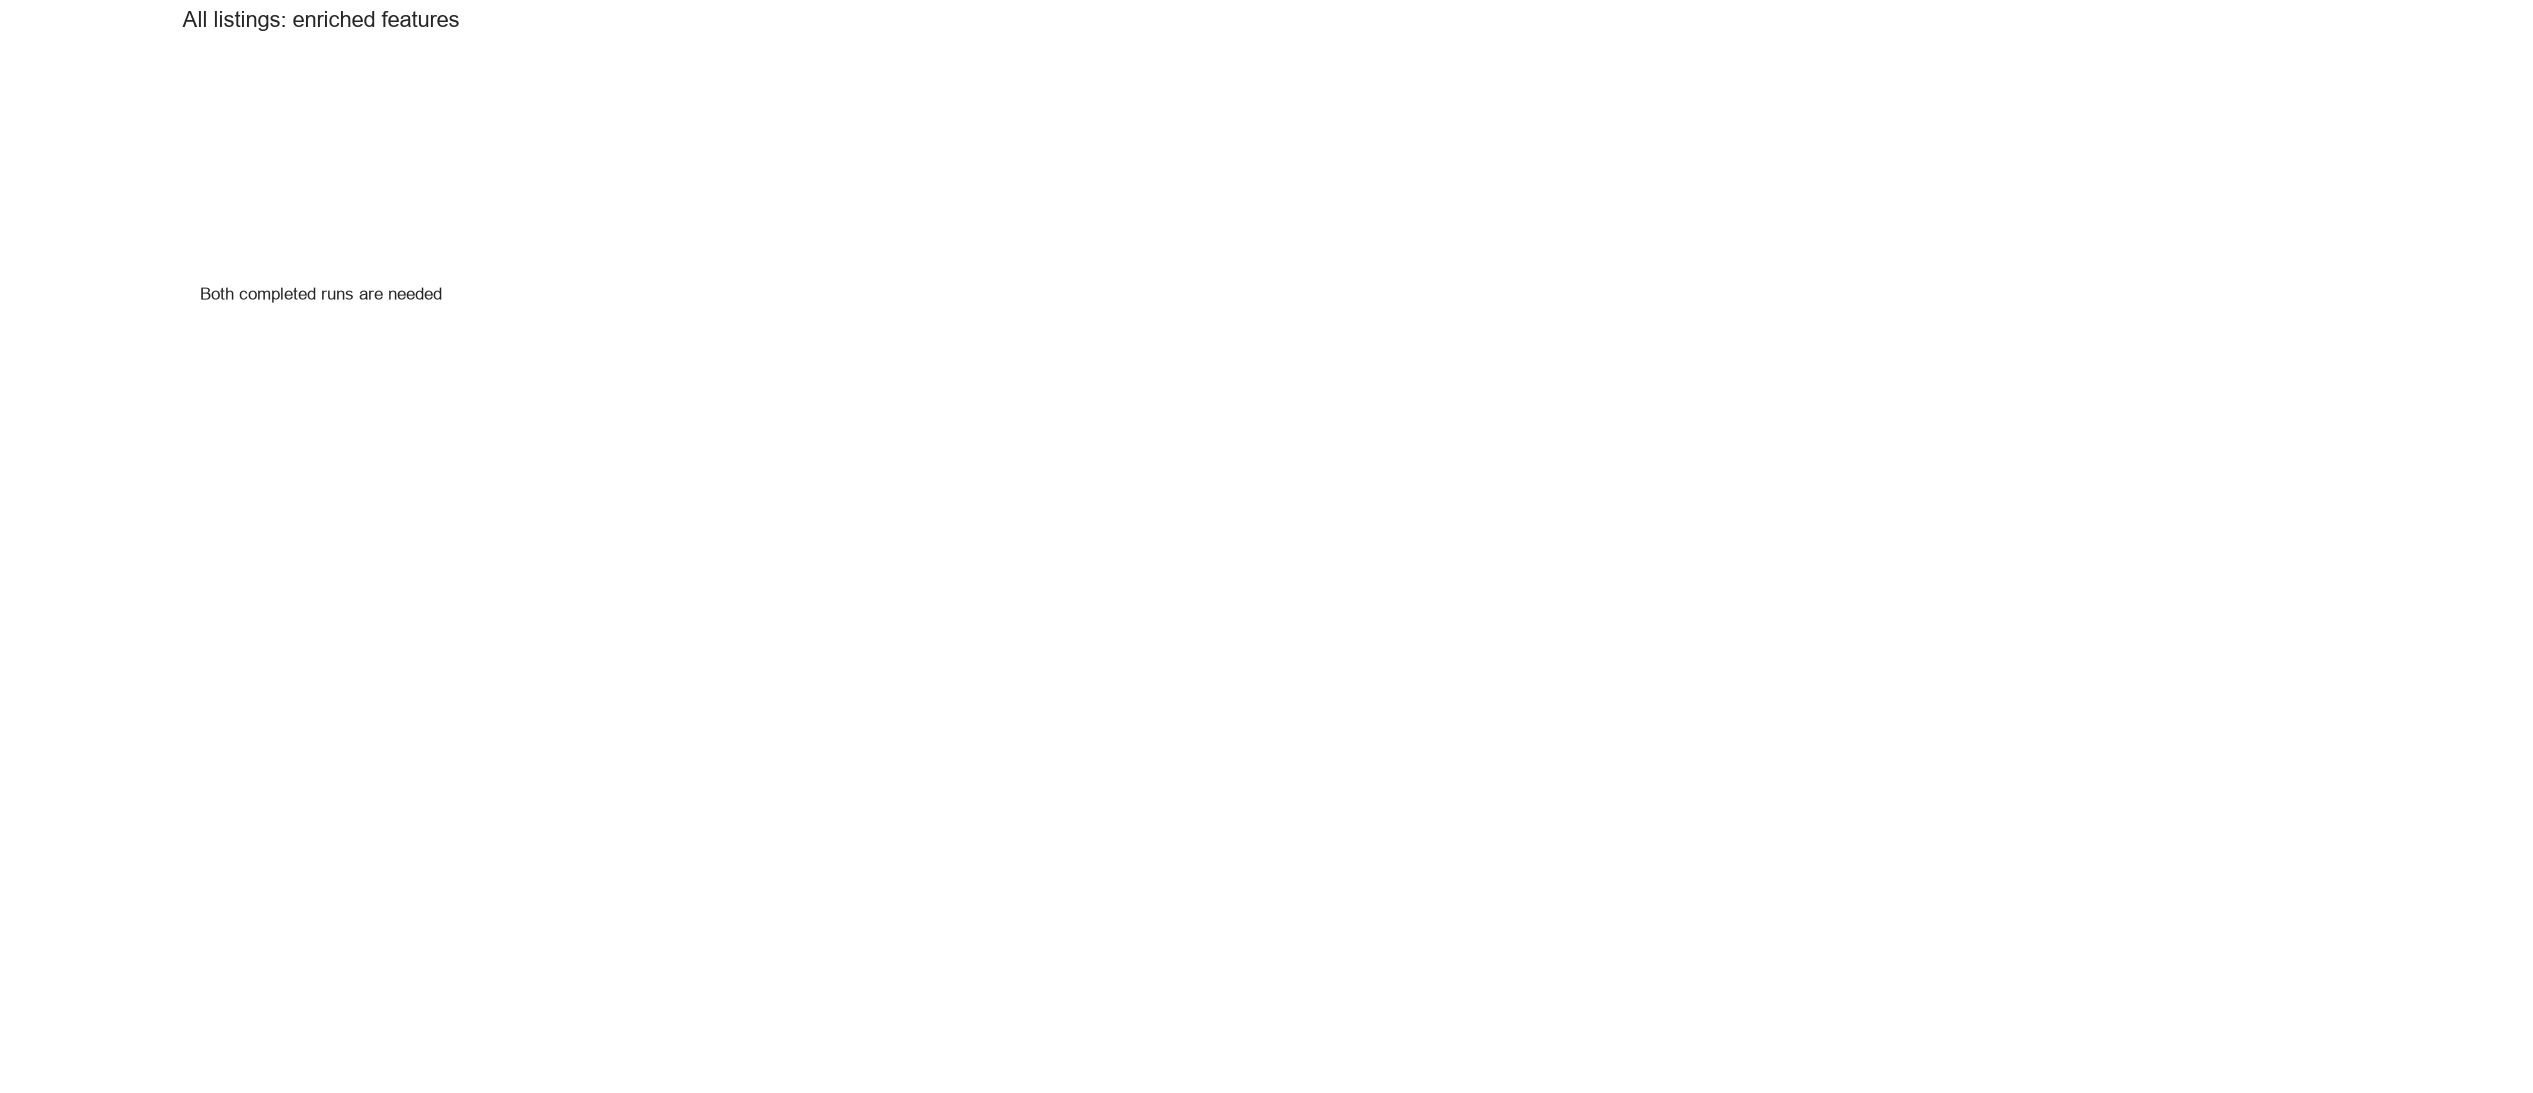

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def completed_runs(model_type):
    folder = MODEL_OUTPUT_DIR / model_type
    runs = []
    if folder.is_dir():
        for path in sorted(folder.iterdir(), key=lambda item: item.name, reverse=True):
            meta_file = path / "run_metadata.json"
            if path.is_dir() and (path / "metrics.csv").is_file() and meta_file.is_file():
                meta = json.loads(meta_file.read_text(encoding="utf-8"))
                if meta.get("status", "completed") == "completed":
                    runs.append(path)
    override = RUN_PATHS.get(model_type)
    if override:
        path = Path(override)
        if not path.is_absolute(): path = PROJECT_ROOT / path
        if path not in runs:
            raise ValueError(f"RUN_PATHS[{model_type!r}] must identify a completed MODEL_OUTPUT run")
        return [path] + [run for run in runs if run != path]
    return runs

COMPARISON_PAIRS = [
    ("base", "enriched", "All listings: enriched features"),
]

comparison_run, comparison_meta, comparison_metrics = {}, {}, {}
for kind in COMPARISON_MODEL_TYPES:
    available = completed_runs(kind)
    if available:
        comparison_run[kind] = available[0]
        comparison_meta[kind] = json.loads((available[0] / "run_metadata.json").read_text(encoding="utf-8"))
        comparison_metrics[kind] = pd.read_csv(available[0] / "metrics.csv").set_index("model")

forecast_rows = []
paired_segment_rows = []
for kind, run_path in comparison_run.items():
    meta, scores = comparison_meta[kind], comparison_metrics[kind]
    selected = meta.get("selected_by_validation_mae")
    eligible = scores.drop(index=["training_median_baseline"], errors="ignore").reset_index()
    eligible = eligible.dropna(subset=["validation_mae"])
    if selected not in eligible.model.to_list() and not eligible.empty:
        selected = eligible.sort_values("validation_mae").iloc[0]["model"]
    winner = scores.loc[selected] if selected in scores.index else None
    baseline_score = scores.loc["training_median_baseline"] if "training_median_baseline" in scores.index else None
    forecast_rows.append({
        "feature set": kind, "eligible listings": meta.get("rows_after_filters"),
        "test listings": meta.get("test_rows"), "test split groups": meta.get("test_split_groups"),
        "predictors": len(meta.get("raw_feature_columns", [])), "selected ML model": selected,
        "validation MAE (USD)": None if winner is None else winner["validation_mae"],
        "ML test MAE (USD)": None if winner is None else winner["mae"],
        "ML test RMSE (USD)": None if winner is None else winner["rmse"],
        "ML test R²": None if winner is None else winner.get("r2"),
        "ML validation R²": None if winner is None else winner.get("validation_r2"),
        "training weighting": meta.get("price_weighting", "none"),
        "median-baseline test MAE (USD)": None if baseline_score is None else baseline_score["mae"],
    })
if forecast_rows:
    display(pd.DataFrame(forecast_rows).set_index("feature set").style.format({
        "validation MAE (USD)": "USD {:,.0f}", "test MAE (USD)": "USD {:,.0f}",
        "test RMSE (USD)": "USD {:,.0f}", "ML test R²": "{:.4f}", "ML validation R²": "{:.4f}", "eligible listings": "{:,.0f}",
        "test listings": "{:,.0f}", "test split blocks": "{:,.0f}"}, na_rep="—"))
else:
    display(Markdown("No completed runs are available yet. Train matched feature sets, then rerun the notebook."))

fig, axes = plt.subplots(2, 4, figsize=(21, 9), constrained_layout=True)
paired_rows, any_plot = [], False
rng = np.random.default_rng(42)
for ax, (reference, expanded, label) in zip(axes.flat, COMPARISON_PAIRS):
    if reference not in comparison_run or expanded not in comparison_run:
        ax.set_title(label); ax.text(.5, .5, "Both completed runs are needed", ha="center", va="center")
        ax.set_axis_off(); continue
    left, right = comparison_meta[reference], comparison_meta[expanded]
    if not compatible_run_metadata(left, right, allow_feature_set=True):
        paired_rows.append({"comparison": f"{reference} vs {expanded}", "status": "incompatible run fingerprints"})
        ax.set_title(label); ax.text(.5, .5, "Run fingerprints differ", ha="center", va="center")
        ax.set_axis_off(); continue
    common = sorted((set(comparison_metrics[reference].index) & set(comparison_metrics[expanded].index)) - {"training_median_baseline"})
    chart_rows = []
    for model in common:
        lp = pd.read_parquet(comparison_run[reference] / f"{model}_test_predictions.parquet")
        rp = pd.read_parquet(comparison_run[expanded] / f"{model}_test_predictions.parquet")
        columns = ["vin", "actual_price", "prediction", "split_group", "ModelYear", "Make", "family_block"]
        pair = lp[columns].merge(rp[columns], on="vin", suffixes=("_ref", "_expanded"), validate="one_to_one")
        same_rows = (len(pair) == len(lp) == len(rp)
                     and np.allclose(pair.actual_price_ref, pair.actual_price_expanded)
                     and (pair.split_group_ref == pair.split_group_expanded).all()
                     and pair.ModelYear_ref.equals(pair.ModelYear_expanded)
                     and pair.Make_ref.equals(pair.Make_expanded))
        if not same_rows:
            paired_rows.append({"comparison": f"{reference} vs {expanded}", "model": model, "status": "held-out rows/groups differ"})
            continue
        pair["reference_error"] = (pair.prediction_ref-pair.actual_price_ref).abs()
        pair["expanded_error"] = (pair.prediction_expanded-pair.actual_price_expanded).abs()
        group_errors = pair.groupby("split_group_ref")[["reference_error", "expanded_error"]].mean()
        group_delta = (group_errors.expanded_error-group_errors.reference_error).to_numpy()
        bootstrap = np.array([group_delta[rng.integers(0,len(group_delta),len(group_delta))].mean() for _ in range(2000)])
        mae_ref, mae_exp = pair.reference_error.mean(), pair.expanded_error.mean()
        paired_rows.append({"comparison": f"{reference} vs {expanded}", "model": model,
            "test listings": len(pair), "reference MAE (USD)": mae_ref, "expanded MAE (USD)": mae_exp,
            "expanded minus reference MAE (USD)": mae_exp-mae_ref,
            "group-macro MAE change (USD)": group_delta.mean(),
            "paired group bootstrap 95% low": np.quantile(bootstrap,.025),
            "paired group bootstrap 95% high": np.quantile(bootstrap,.975),
            "held-out groups": len(group_delta), "status": "same held-out listings"})
        chart_rows.append((model,mae_ref,mae_exp))
        for level, cols in (("year", ["ModelYear_ref"]), ("make", ["Make_ref"]),
                            ("year_make", ["ModelYear_ref", "Make_ref"])):
            for key, part in pair.groupby(cols, observed=True, dropna=False, sort=True):
                values = key if isinstance(key, tuple) else (key,)
                item = {"comparison": f"{reference} vs {expanded}", "model": model,
                        "metric_level": level, "ModelYear": None, "Make": None}
                item.update(dict(zip(["ModelYear", "Make"],
                    values if level == "year_make" else ((values[0], None) if level == "year" else (None, values[0])))))
                ref_mae = float(part.reference_error.mean())
                exp_mae = float(part.expanded_error.mean())
                family_count = int(part.family_block_ref.nunique(dropna=False))
                item.update({"rows": len(part), "family_blocks": family_count,
                    "reference_mae_usd": ref_mae, "enriched_mae_usd": exp_mae,
                    "enriched_minus_base_mae_usd": exp_mae-ref_mae,
                    "support_status": "supported" if len(part) >= 100 and family_count >= 5 else "low_support"})
                paired_segment_rows.append(item)
    if chart_rows:
        pd.DataFrame(chart_rows,columns=["model","reference","expanded"]).set_index("model").plot(
            kind="barh",ax=ax,color=["#5470C6","#91CC75"],width=.78)
        ax.set_title(label); ax.set_xlabel("Held-out MAE (USD)"); ax.set_ylabel("")
        ax.legend([reference,expanded],frameon=False); ax.grid(axis="x",alpha=.25); any_plot=True
    else:
        ax.set_title(label); ax.text(.5,.5,"No shared model prediction files",ha="center",va="center"); ax.set_axis_off()
for ax in list(axes.flat)[len(COMPARISON_PAIRS):]: ax.set_axis_off()
if any_plot: plt.show()
if paired_rows:
    display(Markdown("**Matched test-set comparisons.** Negative expanded-minus-reference values mean lower row-weighted MAE. Intervals resample split groups and summarize the group-macro MAE change; they are conditional on the fitted runs."))
    display(pd.DataFrame(paired_rows))
if paired_segment_rows:
    paired_segments = pd.DataFrame(paired_segment_rows)
    display(paired_segments[paired_segments.metric_level == "year_make"].sort_values(
        ["ModelYear", "Make"], na_position="last").style.format({
            "reference_mae_usd": "USD {:,.0f}", "enriched_mae_usd": "USD {:,.0f}",
            "enriched_minus_base_mae_usd": "USD {:,.0f}", "rows": "{:,.0f}",
            "family_blocks": "{:,.0f}"}, na_rep="—"))

coverage_rows=[]
display(Markdown("Source-specific feature-set ablations have been consolidated into `enriched`."))


## Ordinary versus capped price weighting

In [16]:
weighting_overview, weighting_segments = [], []
for kind in COMPARISON_MODEL_TYPES:
    treatments = {}
    for run_path in completed_runs(kind):
        run_meta = json.loads((run_path / "run_metadata.json").read_text(encoding="utf-8"))
        mode = run_meta.get("price_weighting", "none")
        treatments.setdefault(mode, (run_path, run_meta))
    if not {"none", "high_price"}.issubset(treatments):
        continue
    ordinary_path, ordinary_meta = treatments["none"]
    weighted_path, weighted_meta = treatments["high_price"]
    if not compatible_run_metadata(ordinary_meta, weighted_meta, allow_price_weighting=True):
        display(Markdown(f"{kind}: ordinary and weighted runs have different source/split/settings fingerprints."))
        continue
    for phase, filename, prefix in [("validation", "validation_metrics.csv", "validation_"),
                                    ("test", "metrics.csv", "")]:
        if not all((path / filename).is_file() for path in [ordinary_path, weighted_path]):
            continue
        ordinary = pd.read_csv(ordinary_path / filename).set_index("model")
        weighted = pd.read_csv(weighted_path / filename).set_index("model")
        for model in ordinary.index.intersection(weighted.index):
            row = {"feature_set": kind, "phase": phase, "model": model}
            for metric in ["mae", "rmse", "r2", "wape_pct"]:
                left = ordinary.loc[model].get(prefix + metric, np.nan)
                right = weighted.loc[model].get(prefix + metric, np.nan)
                row.update({f"{metric}_none": left, f"{metric}_high_price": right,
                            f"{metric}_change": right - left})
            weighting_overview.append(row)
        segment_file = "validation_segment_metrics.csv" if phase == "validation" else "segment_metrics.csv"
        if not all((path / segment_file).is_file() for path in [ordinary_path, weighted_path]):
            continue
        ordinary_segments = pd.read_csv(ordinary_path / segment_file)
        weighted_segments = pd.read_csv(weighted_path / segment_file)
        pairs = ordinary_segments.merge(weighted_segments, on=["model", "dimension", "segment"],
                                         suffixes=("_none", "_high_price"), validate="one_to_one")
        focus = ((pairs.dimension == "price_band") |
                 ((pairs.dimension == "make_name") & pairs.segment.str.upper().isin(
                     ["FERRARI", "LAMBORGHINI", "MCLAREN", "ASTON MARTIN", "BENTLEY", "ROLLS-ROYCE"])))
        pairs = pairs[focus].copy()
        pairs["feature_set"], pairs["phase"] = kind, phase
        for metric in ["mae", "rmse", "r2", "wape_pct", "mean_signed_error"]:
            if metric + "_none" in pairs and metric + "_high_price" in pairs:
                pairs[metric + "_change"] = pairs[metric + "_high_price"] - pairs[metric + "_none"]
        weighting_segments.append(pairs)
if weighting_overview:
    display(pd.DataFrame(weighting_overview).sort_values(["feature_set", "phase", "model"]))
    if weighting_segments:
        display(pd.concat(weighting_segments, ignore_index=True))
else:
    display(Markdown("No matched ordinary/weighted price-runner pair is available. Run with --price-weightings none high_price, then rerun this notebook. NHTSA text runs have their own validation_weighting_comparison.csv and test_weighting_comparison.csv."))


No matched ordinary/weighted price-runner pair is available. Run with --price-weightings none high_price, then rerun this notebook. NHTSA text runs have their own validation_weighting_comparison.csv and test_weighting_comparison.csv.